# RTM–WB GNW Mean-Field Model

This is the main GNW integration model. It replaces the slow Brian2 cell-by-cell RTM/WB network with one excitatory and one inhibitory **population-rate** state per anatomical brain area. The excitatory rate represents the RTM population; the inhibitory rate represents the local WB population. The 40-area FLN matrix, V4 stimulus, workspace ignition readout, local recurrence, and workspace feedback remain represented.

**Run this notebook from top to bottom.** The primary notebook path is `final_notebooks/RTM-WB GNW Integration.ipynb`. This model produces continuous rates, not individual voltage traces or spike events. Its transfer curves and coupling values are phenomenological and should be treated as a rate-model approximation, rather than a mathematically derived reduction of the original RTM/WB differential equations.

The earlier Brian2 cell-network implementation is preserved in `final_notebooks/RTM-WB GNW Spiking Reference.ipynb` for comparison.

## Step 1: Load area labels and the anatomical FLN matrix

The connectivity file stores FLN with rows as target areas and columns as source areas. We apply the same power transform and incoming-row normalization used by the spiking GNW notebook, so each target's retained input weights sum to at most one.

In [13]:
from pathlib import Path
import sys

project_root = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "data").is_dir() and (p / "template_kwargs.py").is_file()),
    None,
)
if project_root is None:
    raise RuntimeError("Start Jupyter from the project root or one of its subdirectories.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from template_kwargs import template_kwargs

connectivity_path = project_root / "data" / template_kwargs["connectivity_file"]
with open(connectivity_path, "rb") as f:
    anatomy = np.load(f, allow_pickle=True, encoding="bytes")

area_labels = [
    x.decode("utf-8") if isinstance(x, bytes) else str(x)
    for x in anatomy[b"area_list"]
]
raw_fln = np.asarray(anatomy[b"fln"], dtype=float)
assert raw_fln.shape == (len(area_labels), len(area_labels))
assert len(area_labels) == 40

fln_a = float(template_kwargs["fln_a"])
fln_b = float(template_kwargs["fln_b"])
scaled_fln = fln_a * np.clip(raw_fln, 0.0, None) ** fln_b
row_totals = np.nansum(scaled_fln, axis=1, keepdims=True)
fln_weights = np.divide(
    scaled_fln,
    row_totals,
    out=np.zeros_like(scaled_fln),
    where=row_totals > 0,
)
fln_weights = np.nan_to_num(fln_weights)

n_areas = len(area_labels)
v4_idx = area_labels.index("V4")
workspace_areas = ["F1", "F2", "F3", "F4", "7a", "7b"]
workspace_indices = np.asarray([area_labels.index(a) for a in workspace_areas], dtype=int)
workspace_mask = np.zeros(n_areas, dtype=float)
workspace_mask[workspace_indices] = 1.0

print("Areas:", n_areas)
print("FLN matrix shape:", fln_weights.shape)
print("Stimulus source:", area_labels[v4_idx])
print("Workspace:", workspace_areas)

Areas: 40
FLN matrix shape: (40, 40)
Stimulus source: V4
Workspace: ['F1', 'F2', 'F3', 'F4', '7a', '7b']


## Step 2: Check actual FLN directions inside the workspace

The adjacency matrix below is directed: row `i`, column `j` means `j → i`. Existing reciprocal FLN pairs are kept as they are. For a one-way anatomical link, the optional feedback matrix adds only the missing reverse direction, using the weight of the observed FLN edge as its scale. The feedback gain remains independent from the original FLN gain.

In [14]:
workspace_fln = fln_weights[np.ix_(workspace_indices, workspace_indices)].copy()
np.fill_diagonal(workspace_fln, 0.0)
workspace_adj = workspace_fln > 0
n_possible_directed = len(workspace_areas) * (len(workspace_areas) - 1)
n_possible_pairs = n_possible_directed // 2
n_directed = int(workspace_adj.sum())
n_mutual_pairs = sum(
    bool(workspace_adj[i, j] and workspace_adj[j, i])
    for i in range(len(workspace_areas))
    for j in range(i + 1, len(workspace_areas))
)

# The dynamics include all 40 areas, so use a full-area feedback matrix.
feedback_weights = np.zeros_like(fln_weights)
feedback_edges = []
for target_local, source_local in np.argwhere(workspace_adj):
    if not workspace_adj[source_local, target_local]:
        source_area = int(workspace_indices[target_local])
        target_area = int(workspace_indices[source_local])
        edge_weight = float(workspace_fln[target_local, source_local])
        feedback_weights[target_area, source_area] = edge_weight
        feedback_edges.append((source_area, target_area, edge_weight))

assert feedback_weights.shape == fln_weights.shape == (n_areas, n_areas), (feedback_weights.shape, fln_weights.shape)

print("Directed FLN adjacency (rows=target, columns=source):")
print(pd.DataFrame(workspace_adj.astype(int), index=workspace_areas, columns=workspace_areas))
print(f"Anatomical directed paths: {n_directed}/{n_possible_directed}")
print(f"Reciprocal area pairs: {n_mutual_pairs}/{n_possible_pairs}")
print("Added reverse-path candidates:")
for source_area, target_area, _ in feedback_edges:
    print(f"  {area_labels[source_area]} -> {area_labels[target_area]}")

Directed FLN adjacency (rows=target, columns=source):
    F1  F2  F3  F4  7a  7b
F1   0   1   1   1   1   0
F2   1   0   1   1   1   1
F3   1   1   0   1   1   1
F4   1   1   1   0   1   1
7a   1   1   1   0   0   1
7b   1   1   1   1   1   0
Anatomical directed paths: 28/30
Reciprocal area pairs: 13/15
Added reverse-path candidates:
  F4 -> 7a
  7b -> F1


## Step 3: Set up the mean-field model

Each area's state is an average excitatory rate `rE` and inhibitory rate `rI`, plus low-pass synaptic activity `sE` and `sI`. The shared transfer, initialization, and one-step E/I/synapse update now live in `gnw_mean_field.py`; smaller models can use the same interface.

- RTM-like excitatory activity receives the V4 drive, local recurrence in workspace areas, FLN input, optional added reverse feedback, and WB-like inhibition.
- WB-like inhibitory activity is recruited by excitatory activity and feeds back inhibition locally.
- Rates pass through bounded sigmoid transfer functions.

The gains are **dimensionless screening values**, not the spiking model's mS/cm² conductances. The present transfer functions are provisional; fit them to local RTM–WB population input/output data before treating the values as biologically calibrated.

In [15]:
from gnw_mean_field import (
    GNWMeanFieldParameters,
    initialize_mean_field_state,
    mean_field_step,
    sigmoid_rate,
)

# Simulation window matches the preceding extended spiking experiment.
duration_ms = 800.0
dt_ms = 1.0
time_ms = np.arange(0.0, duration_ms + dt_ms, dt_ms)
stimulus_on_ms = 50.0
stimulus_off_ms = 500.0
pulse_drive = 0.4  # provisional starting point; screened in Step 4

# Population-rate transfer and time constants (provisional).
rE_max_hz = 80.0
rI_max_hz = 60.0
tau_E_ms = 10.0
tau_I_ms = 8.0
tau_sE_ms = 8.0
tau_sI_ms = 8.0
theta_E = 0.30
slope_E = 0.12  # softened from 0.08 after the first scan jumped from quiet to saturation
theta_I = 0.60
slope_I = 0.12

# Local E/I balance and anatomical FLN drive (dimensionless).
J_EI = 1.2   # E -> I recruitment
J_IE = 0.8   # I -> E inhibition
J_II = 0.3   # I -> I inhibition
G_FLN = 1.0  # provisional starting point; screened in Step 4

ignition_threshold_hz = 20.0
ignition_min_duration_ms = 50.0


gnw_mf_params = GNWMeanFieldParameters(
    rE_max_hz=rE_max_hz,
    rI_max_hz=rI_max_hz,
    tau_E_ms=tau_E_ms,
    tau_I_ms=tau_I_ms,
    tau_sE_ms=tau_sE_ms,
    tau_sI_ms=tau_sI_ms,
    theta_E=theta_E,
    slope_E=slope_E,
    theta_I=theta_I,
    slope_I=slope_I,
    J_EI=J_EI,
    J_IE=J_IE,
    J_II=J_II,
)


def simulate_mean_field(
    local_recurrent_gain=0.0,
    workspace_feedback_gain=0.0,
    pulse_drive_value=None,
    fln_gain_value=None,
    input_noise_sd=0.0,
    random_seed=None,
):
    """Simulate 40 E/I populations with directed FLN and optional workspace feedback."""
    pulse_drive_used = pulse_drive if pulse_drive_value is None else float(pulse_drive_value)
    fln_gain_used = G_FLN if fln_gain_value is None else float(fln_gain_value)
    if feedback_weights.shape != (n_areas, n_areas):
        raise ValueError(
            f"feedback_weights shape is {feedback_weights.shape}; expected {(n_areas, n_areas)}. "
            "Reload the updated notebook and re-run the FLN audit cell before this step."
        )
    rng = np.random.default_rng(random_seed)
    n_time = len(time_ms)
    rE = np.zeros((n_time, n_areas), dtype=float)
    rI = np.zeros((n_time, n_areas), dtype=float)
    sE = np.zeros_like(rE)
    sI = np.zeros_like(rI)

    # Shared GNW mean-field interface: same transfer curves and state initialization.
    rE[0, :], rI[0, :], sE[0, :], sI[0, :] = initialize_mean_field_state(
        n_areas, gnw_mf_params
    )

    for k in range(1, n_time):
        now_ms = time_ms[k - 1]
        drive = np.zeros(n_areas, dtype=float)
        if stimulus_on_ms <= now_ms < stimulus_off_ms:
            drive[v4_idx] = pulse_drive_used

        input_noise = (
            rng.normal(0.0, input_noise_sd, size=n_areas)
            if input_noise_sd > 0.0 else 0.0
        )
        additive_e_input = (
            drive
            + input_noise
            + local_recurrent_gain * workspace_mask * sE[k - 1]
            + fln_gain_used * (fln_weights @ sE[k - 1])
            + workspace_feedback_gain * (feedback_weights @ sE[k - 1])
        )
        rE[k], rI[k], sE[k], sI[k] = mean_field_step(
            rE[k - 1], rI[k - 1], sE[k - 1], sI[k - 1],
            additive_e_input, dt_ms, gnw_mf_params,
        )

    return {"time_ms": time_ms.copy(), "rE_hz": rE, "rI_hz": rI}


def meanfield_metrics(result):
    """Measure stimulus-evoked ignition and early/late regional rates."""
    rates = result["rE_hz"]
    workspace_mean = rates[:, workspace_indices].mean(axis=1)
    above = workspace_mean >= ignition_threshold_hz
    required_samples = int(np.ceil(ignition_min_duration_ms / dt_ms))
    onset_edges = np.flatnonzero(above & ~np.r_[False, above[:-1]])
    ignition_start = None
    for start_idx in onset_edges:
        if time_ms[start_idx] < stimulus_on_ms:
            continue
        stop_idx = start_idx + required_samples
        if stop_idx <= len(above) and np.all(above[start_idx:stop_idx]):
            ignition_start = int(start_idx)
            break
    ignited = ignition_start is not None
    ignition_time = float(time_ms[ignition_start]) if ignited else np.nan
    pre_stim = time_ms < stimulus_on_ms
    during_stim = (time_ms >= stimulus_on_ms) & (time_ms < stimulus_off_ms)
    early = (time_ms >= 500.0) & (time_ms < 650.0)
    late = (time_ms >= 650.0) & (time_ms <= 800.0)
    return {
        "workspace_mean_hz": workspace_mean,
        "mean_workspace_rate_pre_stim_hz": float(workspace_mean[pre_stim].mean()),
        "max_workspace_mean_pre_stim_hz": float(workspace_mean[pre_stim].max()),
        "ignited": ignited,
        "ignition_time_ms": ignition_time,
        "ignition_latency_ms": ignition_time - stimulus_on_ms if ignited else np.nan,
        "v4_mean_rate_during_stim_hz": float(rates[during_stim, v4_idx].mean()),
        "workspace_mean_rate_during_stim_hz": float(workspace_mean[during_stim].mean()),
        "mean_workspace_rate_500_650ms_hz": float(workspace_mean[early].mean()),
        "mean_workspace_rate_650_800ms_hz": float(workspace_mean[late].mean()),
        "workspace_areas_active_650_800": int(np.count_nonzero(rates[late][:, workspace_indices].mean(axis=0) >= ignition_threshold_hz)),
        "max_workspace_mean_hz": float(workspace_mean.max()),
        "max_workspace_area_rate_hz": float(rates[:, workspace_indices].max()),
        "workspace_time_above_threshold_after_stim_ms": float(np.count_nonzero((workspace_mean >= ignition_threshold_hz) & (time_ms >= stimulus_off_ms)) * dt_ms),
    }

print("Mean-field model functions defined.")

Mean-field model functions defined.


## Step 4: Find a non-saturated, stimulus-evoked operating point

The previous defaults drove the workspace to the 80 Hz ceiling. This cell first varies only V4 drive and the original FLN gain, with added recurrence and feedback disabled. It rejects points with high pre-stimulus activity, no stimulus-evoked ignition, or saturated rates. A moderate candidate is selected for the subsequent recurrence/feedback scan; inspect the table and plot before interpreting it.
The first scan jumped from low activity to rates near the 80 Hz ceiling. A denser follow-up scan softened the excitatory transfer slope to 0.12 and narrowed the FLN range. The selected point is a numerical working point for testing feedback; transfer parameters remain provisional.


Input/FLN scan with added recurrence and feedback disabled:
 pulse_drive  G_FLN  ignited  pre_stim_workspace_mean_hz  pre_stim_workspace_peak_hz  ignition_latency_ms  v4_mean_rate_during_stim_hz  workspace_mean_rate_during_stim_hz  mean_workspace_rate_650_800ms_hz  max_workspace_area_rate_hz  workspace_areas_active_650_800
        0.20   0.75    False                       9.209                      10.824                  NaN                       28.027                              12.076                            11.741                      12.780                               0
        0.20   0.85    False                      10.201                      12.881                  NaN                       32.979                              17.504                            16.858                      18.832                               0
        0.20   0.90     True                      10.815                      14.302                 44.0                       36.535           

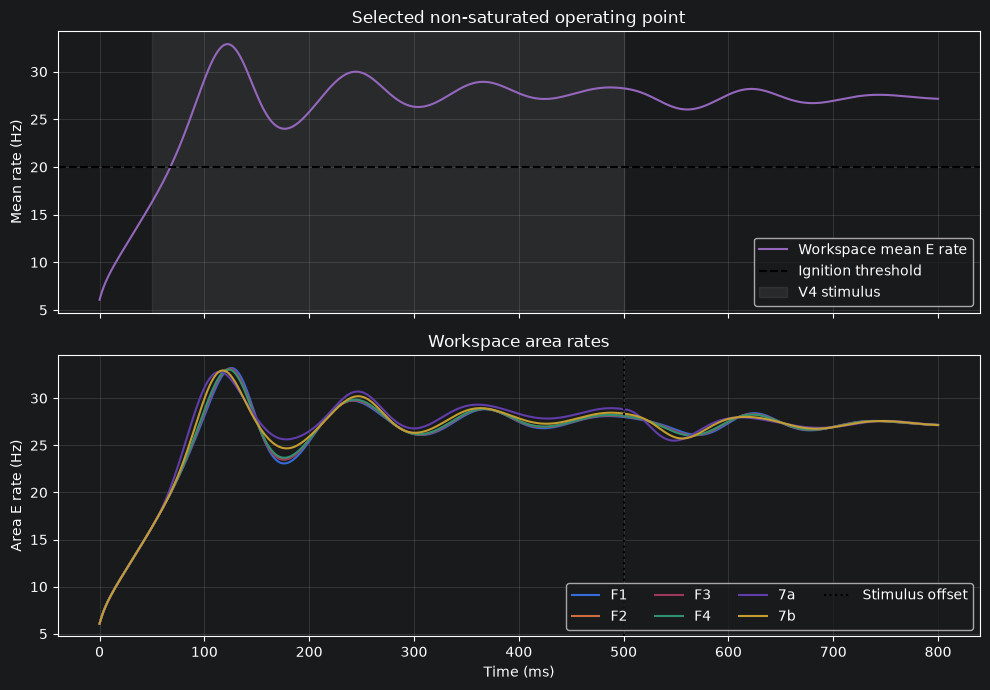

In [16]:
pulse_drive_levels = [0.2, 0.35, 0.5, 0.65]
fln_gain_levels = [0.75, 0.85, 0.9, 0.95, 1.0, 1.05, 1.1, 1.15, 1.2, 1.25]
operating_rows = []

for drive_value in pulse_drive_levels:
    for fln_value in fln_gain_levels:
        trial = simulate_mean_field(
            local_recurrent_gain=0.0,
            workspace_feedback_gain=0.0,
            pulse_drive_value=drive_value,
            fln_gain_value=fln_value,
        )
        metrics = meanfield_metrics(trial)
        operating_rows.append({
            "pulse_drive": drive_value,
            "G_FLN": fln_value,
            "ignited": metrics["ignited"],
            "pre_stim_workspace_mean_hz": metrics["mean_workspace_rate_pre_stim_hz"],
            "pre_stim_workspace_peak_hz": metrics["max_workspace_mean_pre_stim_hz"],
            "ignition_latency_ms": metrics["ignition_latency_ms"],
            "v4_mean_rate_during_stim_hz": metrics["v4_mean_rate_during_stim_hz"],
            "workspace_mean_rate_during_stim_hz": metrics["workspace_mean_rate_during_stim_hz"],
            "mean_workspace_rate_650_800ms_hz": metrics["mean_workspace_rate_650_800ms_hz"],
            "max_workspace_area_rate_hz": metrics["max_workspace_area_rate_hz"],
            "workspace_areas_active_650_800": metrics["workspace_areas_active_650_800"],
        })
        del trial

operating_point_scan = pd.DataFrame(operating_rows)
operating_point_candidates = operating_point_scan[
    operating_point_scan["ignited"]
    & (operating_point_scan["pre_stim_workspace_peak_hz"] < ignition_threshold_hz)
    & operating_point_scan["v4_mean_rate_during_stim_hz"].between(15.0, 70.0)
    & (operating_point_scan["max_workspace_area_rate_hz"] < 70.0)
]
print("Input/FLN scan with added recurrence and feedback disabled:")
print(operating_point_scan.round(3).to_string(index=False))

operating_point_selected = not operating_point_candidates.empty
if operating_point_selected:
    scores = (
        (operating_point_candidates["v4_mean_rate_during_stim_hz"] - 40.0).abs()
        + (operating_point_candidates["workspace_mean_rate_during_stim_hz"] - 30.0).abs()
    )
    selected = operating_point_candidates.loc[scores.idxmin()]
    pulse_drive = float(selected["pulse_drive"])
    G_FLN = float(selected["G_FLN"])
    print(f"Selected provisional operating point: pulse_drive={pulse_drive:g}, G_FLN={G_FLN:g}")

    baseline = simulate_mean_field(0.0, 0.0)
    baseline_metrics = meanfield_metrics(baseline)
    print({k: v for k, v in baseline_metrics.items() if k != "workspace_mean_hz"})
    fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
    axes[0].plot(time_ms, baseline_metrics["workspace_mean_hz"], color="tab:purple", label="Workspace mean E rate")
    axes[0].axhline(ignition_threshold_hz, color="black", linestyle="--", label="Ignition threshold")
    axes[0].axvspan(stimulus_on_ms, stimulus_off_ms, color="gray", alpha=0.16, label="V4 stimulus")
    axes[0].set_ylabel("Mean rate (Hz)")
    axes[0].set_title("Selected non-saturated operating point")
    axes[0].legend()
    axes[0].grid(alpha=0.25)
    for area in workspace_areas:
        area_idx = area_labels.index(area)
        axes[1].plot(time_ms, baseline["rE_hz"][:, area_idx], label=area)
    axes[1].axvline(stimulus_off_ms, color="black", linestyle=":", label="Stimulus offset")
    axes[1].set_xlabel("Time (ms)")
    axes[1].set_ylabel("Area E rate (Hz)")
    axes[1].set_title("Workspace area rates")
    axes[1].legend(ncol=4)
    axes[1].grid(alpha=0.25)
    plt.tight_layout()
    plt.show()
else:
    print("No operating point passed the screen. Feedback scan will be skipped.")
    print("Adjust the input grid or calibrate the provisional transfer curves first.")

## Step 5: Scan local recurrence and missing-reverse feedback

This scan runs only if Step 4 finds a non-saturated, stimulus-evoked operating point. It varies local RTM recurrence and the separate gain on added reverse FLN paths; V4 drive and the original FLN gain remain fixed. WB inhibition remains unchanged.

In [17]:
if operating_point_selected:
    local_gain_levels = [0.0, 0.025, 0.05, 0.075, 0.1, 0.125, 0.15]
    feedback_gain_levels = [0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0]
    sweep_rows = []
    for local_gain in local_gain_levels:
        for feedback_gain in feedback_gain_levels:
            result = simulate_mean_field(local_gain, feedback_gain)
            metrics = meanfield_metrics(result)
            sweep_rows.append({
                "local_recurrent_gain": local_gain,
                "workspace_feedback_gain": feedback_gain,
                "ignited": metrics["ignited"],
                "ignition_latency_ms": metrics["ignition_latency_ms"],
                "max_workspace_mean_pre_stim_hz": metrics["max_workspace_mean_pre_stim_hz"],
                "mean_workspace_rate_500_650ms_hz": metrics["mean_workspace_rate_500_650ms_hz"],
                "mean_workspace_rate_650_800ms_hz": metrics["mean_workspace_rate_650_800ms_hz"],
                "workspace_areas_active_650_800": metrics["workspace_areas_active_650_800"],
                "workspace_time_above_threshold_after_stim_ms": metrics["workspace_time_above_threshold_after_stim_ms"],
                "max_workspace_mean_hz": metrics["max_workspace_mean_hz"],
                "max_workspace_area_rate_hz": metrics["max_workspace_area_rate_hz"],
            })
            del result
    meanfield_sweep = pd.DataFrame(sweep_rows)
    print("Recurrence/feedback scan at selected operating point:")
    print(meanfield_sweep.round(3).to_string(index=False))
else:
    meanfield_sweep = pd.DataFrame()
    print("Skipped: Step 4 did not find a non-saturated operating point.")

Recurrence/feedback scan at selected operating point:
 local_recurrent_gain  workspace_feedback_gain  ignited  ignition_latency_ms  max_workspace_mean_pre_stim_hz  mean_workspace_rate_500_650ms_hz  mean_workspace_rate_650_800ms_hz  workspace_areas_active_650_800  workspace_time_above_threshold_after_stim_ms  max_workspace_mean_hz  max_workspace_area_rate_hz
                0.000                      0.0     True                 18.0                          16.123                            27.270                            27.200                               6                                         301.0                 32.887                      33.195
                0.000                      1.0     True                 16.0                          16.420                            27.758                            27.685                               6                                         301.0                 33.596                      34.274
                0.000       

### Step 6 — Paired-seed robustness check

The rate model is deterministic unless small input noise is enabled. This check adds the same sized independent input fluctuations to each condition and pairs control and feedback runs by seed. A pass requires stimulus-evoked ignition, no pre-stimulus threshold crossing, activity in all six workspace areas at 650–800 ms, no area above 70 Hz, and a positive paired late-rate effect with a bootstrap 95% confidence interval above zero.

In [18]:
validation_seed_count = 30
validation_seed_values = list(range(100, 100 + validation_seed_count))
validation_noise_sd = 0.005  # small noise in abstract input units; test robustness, not biological calibration
validation_local_gain = 0.05
validation_feedback_levels = [5.0, 6.0]  # confirm the strongest safe edge of the expanded deterministic scan
minimum_pass_fraction = 0.90

control_metrics_by_seed = {}
for seed in validation_seed_values:
    control_result = simulate_mean_field(
        local_recurrent_gain=validation_local_gain,
        workspace_feedback_gain=0.0,
        input_noise_sd=validation_noise_sd,
        random_seed=seed,
    )
    control_metrics_by_seed[seed] = meanfield_metrics(control_result)
    del control_result

robustness_rows = []
paired_effects_by_feedback = {}
for feedback_gain in validation_feedback_levels:
    treatment_metrics = []
    effects = []
    for seed in validation_seed_values:
        treatment_result = simulate_mean_field(
            local_recurrent_gain=validation_local_gain,
            workspace_feedback_gain=feedback_gain,
            input_noise_sd=validation_noise_sd,
            random_seed=seed,
        )
        treatment_metrics.append(meanfield_metrics(treatment_result))
        effects.append(
            treatment_metrics[-1]["mean_workspace_rate_650_800ms_hz"]
            - control_metrics_by_seed[seed]["mean_workspace_rate_650_800ms_hz"]
        )
        del treatment_result

    control_pass = [
        m["max_workspace_mean_pre_stim_hz"] < ignition_threshold_hz
        and m["ignited"]
        and m["workspace_areas_active_650_800"] == len(workspace_areas)
        and m["max_workspace_area_rate_hz"] < 70.0
        for m in control_metrics_by_seed.values()
    ]
    treatment_pass = [
        m["max_workspace_mean_pre_stim_hz"] < ignition_threshold_hz
        and m["ignited"]
        and m["workspace_areas_active_650_800"] == len(workspace_areas)
        and m["max_workspace_area_rate_hz"] < 70.0
        for m in treatment_metrics
    ]
    effects = np.asarray(effects, dtype=float)
    boot_rng = np.random.default_rng(2026)
    bootstrap_means = np.asarray([
        boot_rng.choice(effects, size=len(effects), replace=True).mean()
        for _ in range(5000)
    ])
    ci_low, ci_high = np.percentile(bootstrap_means, [2.5, 97.5])
    robustness_rows.append({
        "feedback_gain": feedback_gain,
        "control_pass_fraction": np.mean(control_pass),
        "feedback_pass_fraction": np.mean(treatment_pass),
        "mean_paired_late_rate_increase_hz": effects.mean(),
        "median_paired_late_rate_increase_hz": np.median(effects),
        "paired_effect_95ci_low_hz": ci_low,
        "paired_effect_95ci_high_hz": ci_high,
        "fraction_seeds_improved": np.mean(effects > 0.0),
    })
    paired_effects_by_feedback[feedback_gain] = effects

robustness_results = pd.DataFrame(robustness_rows)
robustness_results["passed"] = (
    (robustness_results["control_pass_fraction"] >= minimum_pass_fraction)
    & (robustness_results["feedback_pass_fraction"] >= minimum_pass_fraction)
    & (robustness_results["paired_effect_95ci_low_hz"] > 0.0)
    & (robustness_results["fraction_seeds_improved"] >= 0.80)
)
passing = robustness_results[robustness_results["passed"]]
print(f"Paired noisy validation: {validation_seed_count} seeds per condition; input noise SD={validation_noise_sd:g}")
print("Pass rules: >=90% valid trials in each condition; paired late-rate 95% bootstrap CI above zero; >=80% seeds improve.")
print(robustness_results.round(3).to_string(index=False))
if not passing.empty:
    validation_selected_gain = float(passing.iloc[0]["feedback_gain"])
    print(f"ROBUSTNESS PASS at the lowest tested passing feedback gain: {validation_selected_gain:g}")
else:
    validation_selected_gain = None
    print("No tested gain passed all robustness criteria; extend the safe gain/noise scan before claiming robustness.")


Paired noisy validation: 30 seeds per condition; input noise SD=0.005
Pass rules: >=90% valid trials in each condition; paired late-rate 95% bootstrap CI above zero; >=80% seeds improve.
 feedback_gain  control_pass_fraction  feedback_pass_fraction  mean_paired_late_rate_increase_hz  median_paired_late_rate_increase_hz  paired_effect_95ci_low_hz  paired_effect_95ci_high_hz  fraction_seeds_improved  passed
           5.0                    1.0                     1.0                              2.533                                2.531                      2.531                       2.536                      1.0    True
           6.0                    1.0                     1.0                              3.042                                3.038                      3.039                       3.044                      1.0    True
ROBUSTNESS PASS at the lowest tested passing feedback gain: 5


### Step 7 — Visualise the feedback scan


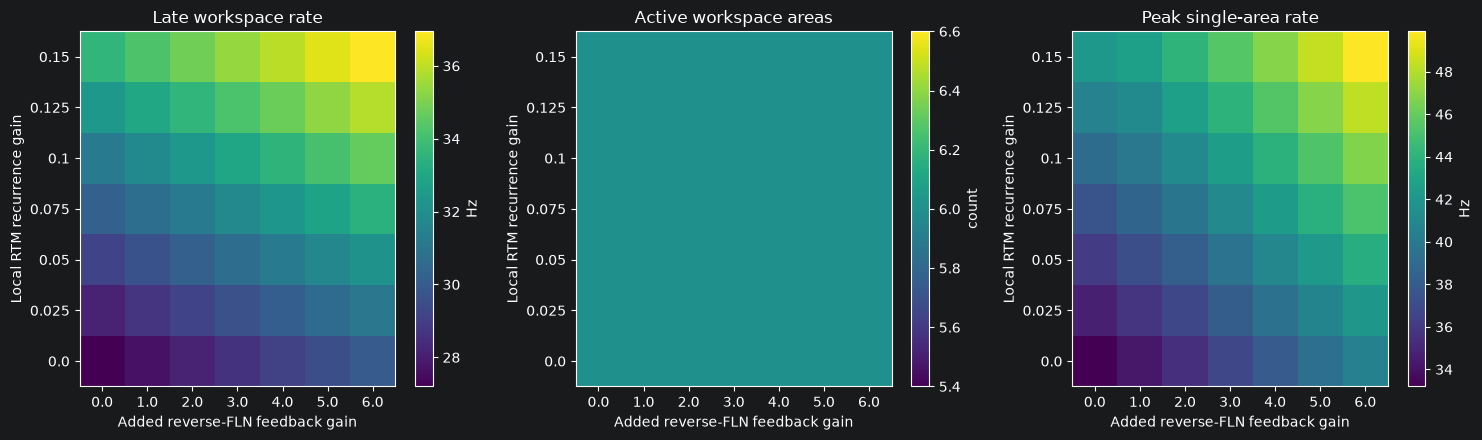

Stable evoked sweep points (includes matched no-feedback controls):
 local_recurrent_gain  workspace_feedback_gain  ignited  ignition_latency_ms  max_workspace_mean_pre_stim_hz  mean_workspace_rate_500_650ms_hz  mean_workspace_rate_650_800ms_hz  workspace_areas_active_650_800  workspace_time_above_threshold_after_stim_ms  max_workspace_mean_hz  max_workspace_area_rate_hz
                0.125                      0.0     True                  0.0                          19.724                            32.210                            32.408                               6                                         301.0                 40.117                      40.630
                0.100                      2.0     True                  0.0                          19.722                            32.199                            32.405                               6                                         301.0                 40.104                      41.133
              

In [19]:
if operating_point_selected and not meanfield_sweep.empty:
    late_rate_grid = meanfield_sweep.pivot(index="local_recurrent_gain", columns="workspace_feedback_gain", values="mean_workspace_rate_650_800ms_hz").reindex(index=local_gain_levels, columns=feedback_gain_levels)
    late_active_grid = meanfield_sweep.pivot(index="local_recurrent_gain", columns="workspace_feedback_gain", values="workspace_areas_active_650_800").reindex(index=local_gain_levels, columns=feedback_gain_levels)
    max_area_grid = meanfield_sweep.pivot(index="local_recurrent_gain", columns="workspace_feedback_gain", values="max_workspace_area_rate_hz").reindex(index=local_gain_levels, columns=feedback_gain_levels)

    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
    for ax, grid, title, cbar_label in [
        (axes[0], late_rate_grid, "Late workspace rate", "Hz"),
        (axes[1], late_active_grid, "Active workspace areas", "count"),
        (axes[2], max_area_grid, "Peak single-area rate", "Hz"),
    ]:
        im = ax.imshow(grid.values, origin="lower", aspect="auto", cmap="viridis")
        ax.set_xticks(np.arange(len(feedback_gain_levels)), feedback_gain_levels)
        ax.set_yticks(np.arange(len(local_gain_levels)), local_gain_levels)
        ax.set_xlabel("Added reverse-FLN feedback gain")
        ax.set_ylabel("Local RTM recurrence gain")
        ax.set_title(title)
        fig.colorbar(im, ax=ax, label=cbar_label)
    plt.tight_layout()
    plt.show()

    candidates = meanfield_sweep[
        meanfield_sweep["ignited"]
        & (meanfield_sweep["max_workspace_mean_pre_stim_hz"] < ignition_threshold_hz)
        & (meanfield_sweep["max_workspace_area_rate_hz"] < 70.0)
    ].sort_values(
        ["workspace_areas_active_650_800", "mean_workspace_rate_650_800ms_hz"], ascending=False
    )
    print("Stable evoked sweep points (includes matched no-feedback controls):")
    print(candidates.head(10).round(3).to_string(index=False))
else:
    print("No feedback plots: the operating-point screen did not pass.")

## Step 7: What this model can and cannot tell us

- It can quickly test whether regional E/I feedback and the FLN graph support late population activity.
- It reports continuous rates; it does **not** generate individual RTM/WB spikes, spike counts, or precise synchrony.
- The extra reverse-FLN feedback is applied only to anatomically one-way workspace pairs. Existing reciprocal FLN links remain unchanged.
- Sigmoid thresholds and gains are provisional. Before using numerical values as scientific estimates, fit the E/I population transfer curves from local spiking RTM–WB simulations and check whether the rate model reproduces the spiking model's baseline and evoked responses.
- Re-run promising gain combinations in the spiking notebook across the same seeds. A mean-field candidate is useful only if the spiking model also shows the intended late activity without runaway rates.
A feedback setting is counted as a successful evoked ignition only if the workspace stays below threshold throughout the pre-stimulus interval, crosses after V4 stimulation begins, and remains below the single-area rate ceiling. A high late rate alone does not count as successful ignition.


### Background

The rate-based E/I approach is related to Wilson–Cowan population models. Mean-field reductions can also be built from spiking networks, but their transfer functions and assumptions need to match the underlying neuron and synapse model. See [a study of time-dependent E/I population rates](https://pmc.ncbi.nlm.nih.gov/articles/PMC3103906/) and [a mean-field treatment of complex spiking neurons](https://pmc.ncbi.nlm.nih.gov/articles/PMC7099478/).

## Step 8: Paired-seed sensitivity scan around the selected mean-field setting

This scan checks whether the late-activity effect persists near the selected operating point. For each local-recurrence value, the no-feedback control is paired with feedback values using the same 30 noise seeds. A candidate passes when at least 90% of both control and feedback trials ignite, all six workspace areas remain active in the late window, the pre-stimulus workspace stays below threshold, and no area's peak rate reaches 70 Hz. The paired late-rate increase must also have a bootstrap 95% interval above zero and improve in at least 80% of seeds.

This is a sensitivity check within the current provisional mean-field equations; it does not calibrate the model to individual-cell RTM/WB spikes.

In [1]:
# Focused paired-seed sensitivity scan around the previously selected point.
sensitivity_local_gains = [0.025, 0.05, 0.075, 0.10]
sensitivity_feedback_gains = [3.0, 4.0, 5.0, 6.0]
sensitivity_seeds = list(validation_seed_values)  # same 30 seeds as the prior robustness check
sensitivity_rows = []
sensitivity_rng = np.random.default_rng(20261116)


def _sensitivity_valid(metrics):
    return bool(
        metrics["max_workspace_mean_pre_stim_hz"] < ignition_threshold_hz
        and metrics["ignited"]
        and metrics["workspace_areas_active_650_800"] == len(workspace_areas)
        and metrics["max_workspace_area_rate_hz"] < 70.0
    )


sensitivity_total_runs = len(sensitivity_local_gains) * len(sensitivity_seeds) * (1 + len(sensitivity_feedback_gains))
try:
    from tqdm.auto import tqdm
    _sensitivity_progress = tqdm(total=sensitivity_total_runs, desc="Paired sensitivity scan", unit="run")
except ImportError:
    _sensitivity_progress = None

for local_gain in sensitivity_local_gains:
    control_by_seed = {}
    for seed in sensitivity_seeds:
        control = simulate_mean_field(
            local_recurrent_gain=local_gain,
            workspace_feedback_gain=0.0,
            input_noise_sd=validation_noise_sd,
            random_seed=seed,
        )
        control_by_seed[seed] = meanfield_metrics(control)
        del control
        if _sensitivity_progress is not None:
            _sensitivity_progress.update(1)

    for feedback_gain in sensitivity_feedback_gains:
        treatment_metrics = []
        paired_effects = []
        for seed in sensitivity_seeds:
            treatment = simulate_mean_field(
                local_recurrent_gain=local_gain,
                workspace_feedback_gain=feedback_gain,
                input_noise_sd=validation_noise_sd,
                random_seed=seed,
            )
            treated = meanfield_metrics(treatment)
            treatment_metrics.append(treated)
            paired_effects.append(
                treated["mean_workspace_rate_650_800ms_hz"]
                - control_by_seed[seed]["mean_workspace_rate_650_800ms_hz"]
            )
            del treatment
            if _sensitivity_progress is not None:
                _sensitivity_progress.update(1)

        paired_effects = np.asarray(paired_effects, dtype=float)
        boot_means = np.asarray([
            sensitivity_rng.choice(paired_effects, size=len(paired_effects), replace=True).mean()
            for _ in range(5000)
        ])
        ci_low, ci_high = np.percentile(boot_means, [2.5, 97.5])
        controls = list(control_by_seed.values())
        sensitivity_rows.append({
            "local_recurrent_gain": local_gain,
            "workspace_feedback_gain": feedback_gain,
            "control_pass_fraction": np.mean([_sensitivity_valid(m) for m in controls]),
            "feedback_pass_fraction": np.mean([_sensitivity_valid(m) for m in treatment_metrics]),
            "mean_late_rate_control_hz": np.mean([m["mean_workspace_rate_650_800ms_hz"] for m in controls]),
            "mean_late_rate_feedback_hz": np.mean([m["mean_workspace_rate_650_800ms_hz"] for m in treatment_metrics]),
            "mean_paired_late_increase_hz": paired_effects.mean(),
            "paired_effect_95ci_low_hz": ci_low,
            "paired_effect_95ci_high_hz": ci_high,
            "fraction_seeds_improved": np.mean(paired_effects > 0.0),
        })

if _sensitivity_progress is not None:
    _sensitivity_progress.close()

sensitivity_results = pd.DataFrame(sensitivity_rows)
sensitivity_results["passed"] = (
    (sensitivity_results["control_pass_fraction"] >= minimum_pass_fraction)
    & (sensitivity_results["feedback_pass_fraction"] >= minimum_pass_fraction)
    & (sensitivity_results["paired_effect_95ci_low_hz"] > 0.0)
    & (sensitivity_results["fraction_seeds_improved"] >= 0.80)
)
print(f"Completed {sensitivity_total_runs} simulations: {len(sensitivity_local_gains)} local gains × {len(sensitivity_feedback_gains)} feedback gains × {len(sensitivity_seeds)} paired seeds (plus matched controls).")
print(sensitivity_results.round(3).to_string(index=False))
print()
print("Passing parameter combinations:")
passing_sensitivity = sensitivity_results[sensitivity_results["passed"]]
print(passing_sensitivity.round(3).to_string(index=False) if not passing_sensitivity.empty else "None passed all criteria.")
if not passing_sensitivity.empty:
    print()
    print("Recommended robust range:")
    print(passing_sensitivity.groupby("local_recurrent_gain")["workspace_feedback_gain"].agg(["min", "max"]).to_string())


Completed 600 simulations: 4 local gains × 4 feedback gains × 30 paired seeds (plus matched controls).
 local_recurrent_gain  workspace_feedback_gain  control_pass_fraction  feedback_pass_fraction  mean_late_rate_control_hz  mean_late_rate_feedback_hz  mean_paired_late_increase_hz  paired_effect_95ci_low_hz  paired_effect_95ci_high_hz  fraction_seeds_improved  passed
                0.025                      3.0                    1.0                     1.0                     28.189                      29.653                         1.464                      1.463                       1.466                      1.0    True
                0.025                      4.0                    1.0                     1.0                     28.189                      30.132                         1.943                      1.941                       1.945                      1.0    True
                0.025                      5.0                    1.0                     1.0   

## Step 9: Test sensitivity to input-noise amplitude

Hold the selected mean-field operating point fixed (`pulse_drive = 0.20`, `G_FLN = 0.95`, local recurrence = 0.05, and workspace feedback = 5.0). Compare feedback-on and matched no-feedback controls across the same 30 seeds at input-noise SDs 0.005, 0.01, and 0.02. The same ignition, pre-stimulus selectivity, late-area coverage, peak-rate, paired-effect confidence interval, and seed-improvement criteria are applied at each noise level.

In [2]:
# Noise robustness at the recommended parameter setting.
noise_sensitivity_levels = [0.005, 0.01, 0.02]
noise_sensitivity_seeds = list(validation_seed_values)
noise_local_gain = 0.05
noise_feedback_gain = 5.0
noise_sensitivity_rng = np.random.default_rng(20261117)
noise_sensitivity_rows = []
noise_total_runs = len(noise_sensitivity_levels) * len(noise_sensitivity_seeds) * 2

try:
    from tqdm.auto import tqdm
    _noise_progress = tqdm(total=noise_total_runs, desc="Noise sensitivity", unit="run")
except ImportError:
    _noise_progress = None

for noise_sd in noise_sensitivity_levels:
    control_by_seed = {}
    feedback_by_seed = {}
    for seed in noise_sensitivity_seeds:
        control_result = simulate_mean_field(
            local_recurrent_gain=noise_local_gain,
            workspace_feedback_gain=0.0,
            input_noise_sd=noise_sd,
            random_seed=seed,
        )
        control_by_seed[seed] = meanfield_metrics(control_result)
        del control_result
        if _noise_progress is not None:
            _noise_progress.update(1)

        feedback_result = simulate_mean_field(
            local_recurrent_gain=noise_local_gain,
            workspace_feedback_gain=noise_feedback_gain,
            input_noise_sd=noise_sd,
            random_seed=seed,
        )
        feedback_by_seed[seed] = meanfield_metrics(feedback_result)
        del feedback_result
        if _noise_progress is not None:
            _noise_progress.update(1)

    paired_effects = np.asarray([
        feedback_by_seed[seed]["mean_workspace_rate_650_800ms_hz"]
        - control_by_seed[seed]["mean_workspace_rate_650_800ms_hz"]
        for seed in noise_sensitivity_seeds
    ])
    boot_means = np.asarray([
        noise_sensitivity_rng.choice(paired_effects, size=len(paired_effects), replace=True).mean()
        for _ in range(5000)
    ])
    ci_low, ci_high = np.percentile(boot_means, [2.5, 97.5])
    control_metrics = list(control_by_seed.values())
    feedback_metrics = list(feedback_by_seed.values())
    noise_sensitivity_rows.append({
        "input_noise_sd": noise_sd,
        "control_pass_fraction": np.mean([_sensitivity_valid(m) for m in control_metrics]),
        "feedback_pass_fraction": np.mean([_sensitivity_valid(m) for m in feedback_metrics]),
        "control_late_rate_hz": np.mean([m["mean_workspace_rate_650_800ms_hz"] for m in control_metrics]),
        "feedback_late_rate_hz": np.mean([m["mean_workspace_rate_650_800ms_hz"] for m in feedback_metrics]),
        "mean_paired_late_increase_hz": paired_effects.mean(),
        "paired_effect_95ci_low_hz": ci_low,
        "paired_effect_95ci_high_hz": ci_high,
        "fraction_seeds_improved": np.mean(paired_effects > 0.0),
    })

if _noise_progress is not None:
    _noise_progress.close()

noise_sensitivity_results = pd.DataFrame(noise_sensitivity_rows)
noise_sensitivity_results["passed"] = (
    (noise_sensitivity_results["control_pass_fraction"] >= minimum_pass_fraction)
    & (noise_sensitivity_results["feedback_pass_fraction"] >= minimum_pass_fraction)
    & (noise_sensitivity_results["paired_effect_95ci_low_hz"] > 0.0)
    & (noise_sensitivity_results["fraction_seeds_improved"] >= 0.80)
)
print(f"Completed {noise_total_runs} simulations: {len(noise_sensitivity_levels)} noise levels × {len(noise_sensitivity_seeds)} paired seeds × control/treatment.")
print(f"Fixed parameters: local recurrence={noise_local_gain:g}, workspace feedback={noise_feedback_gain:g}; pulse={pulse_drive:g}, G_FLN={G_FLN:g}.")
print(noise_sensitivity_results.round(4).to_string(index=False))
print()
print("Passed noise levels:", noise_sensitivity_results.loc[noise_sensitivity_results["passed"], "input_noise_sd"].tolist())


Completed 180 simulations: 3 noise levels × 30 paired seeds × control/treatment.
Fixed parameters: local recurrence=0.05, workspace feedback=5; pulse=0.2, G_FLN=0.95.
 input_noise_sd  control_pass_fraction  feedback_pass_fraction  control_late_rate_hz  feedback_late_rate_hz  mean_paired_late_increase_hz  paired_effect_95ci_low_hz  paired_effect_95ci_high_hz  fraction_seeds_improved  passed
          0.005                    1.0                  1.0000               29.1815                31.7149                        2.5334                     2.5309                      2.5359                      1.0    True
          0.010                    1.0                  1.0000               29.2113                31.7466                        2.5354                     2.5309                      2.5400                      1.0    True
          0.020                    1.0                  0.7667               29.3101                31.8466                        2.5366                  